In [3]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/elliptic-data-set/elliptic_bitcoin_dataset/elliptic_txs_features.csv
/kaggle/input/elliptic-data-set/elliptic_bitcoin_dataset/elliptic_txs_classes.csv
/kaggle/input/elliptic-data-set/elliptic_bitcoin_dataset/elliptic_txs_edgelist.csv


In [4]:
# ---------------------------------------------------------
# 1. INSTALLATIONS & IMPORTS
# ---------------------------------------------------------
!pip install -q node2vec torch-geometric

import os
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.nn import GCNConv, GATConv
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.preprocessing import StandardScaler
from node2vec import Node2Vec
from sklearn.model_selection import train_test_split
import matplotlib as mpl

# Setting device (GPU if available)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Set random seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)

Using device: cuda


<img src="https://www.bitcoinsistemi.com/wp-content/uploads/2023/12/bitcoin.jpg" alt="Bitcoin Graph Image" width="800"/>

# 💰Bitcoin Transactions 🔗 Graph Neural Networks 🪙

This notebook tackles [Kaggles Elliptic Bitcoin Transaction Dataset](https://www.kaggle.com/datasets/ellipticco/elliptic-data-set/data) which maps Bitcoin transactions to real entities. In the description the objective for this dataset is described as:
> classifying the illicit and licit nodes in the graph.

[Wikipedia describes Bitcoin](https://en.wikipedia.org/wiki/Bitcoin) as the first decentralized cryptocurrency. It also states that nodes in the Bitcoin network verify transactions through cryptography and record them in a public distributed ledger, called _blockchain_. The dataset we are going to work on in this notebook is an anonymized transaction graph collexted from such Bitcoin blockchain. Kaggles Data Card describes the dataset as having the following content: 

__Dataset Content__
- _Node_: represents a transaction. 
    - Each has 166 features
    - Labeled as  _licit_,  _illicit_ or  _unknown_
- _Edge_: represents a flow of Bitcoins between transaction `A` and transaction `B` 



# Summary of Node Classification Approaches in the Notebook

| Approach                | Techniques / Features                              | Workflow / Description                                   |
|-------------------------|---------------------------------------------------|---------------------------------------------------------|
| **Traditional Methods** | Node features: degree, closeness, betweenness, clustering coefficient, graphlet counts | Extract node features → Train ML model (e.g., Random Forest) → Node classification |
| **Shallow Methods**     | Node2Vec (random walks + Word2Vec embeddings)    | Generate node embeddings → Train ML model (e.g., logistic regression, RF) → Node classification |
| **GNN Models**          | Graph Convolutional Networks (GCN), Graph Attention Networks (GAT) | Input graph + features → Train GNN → Node classification |


In [5]:
# ---------------------------------------------------------
# 2. DATA LOADING & PROCESSING
# ---------------------------------------------------------
print("Loading Data...")

# Loading datasets 
df_classes = pd.read_csv('/kaggle/input/elliptic-data-set/elliptic_bitcoin_dataset/elliptic_txs_classes.csv')
df_edges = pd.read_csv('/kaggle/input/elliptic-data-set/elliptic_bitcoin_dataset/elliptic_txs_edgelist.csv')
df_features = pd.read_csv('/kaggle/input/elliptic-data-set/elliptic_bitcoin_dataset/elliptic_txs_features.csv', header=None)


# Rename feature columns
# Column 0 is txId, Column 1 is time_step
col_names = ['txId', 'time_step'] + [f'feat_{i}' for i in range(165)]
df_features.columns = col_names

print(f"""Shapes
{4*' '}Features : {df_features.shape[0]:8,} (rows)  {df_features.shape[1]:4,} (cols)
{4*' '}Classes  : {df_classes.shape[0]:8,} (rows)  {df_classes.shape[1]:4,} (cols)
{4*' '}Edgelist : {df_edges.shape[0]:8,} (rows)  {df_edges.shape[1]:4,} (cols)
""")


Loading Data...
Shapes
    Features :  203,769 (rows)   167 (cols)
    Classes  :  203,769 (rows)     2 (cols)
    Edgelist :  234,355 (rows)     2 (cols)



__Nodes & Edges__

- $|V| = 203,768$ (number of nodes in $G$)
- $|E| = 234,355$ (number of edges in $G$)

In [6]:
df_features.head(3)

,txId,time_step,feat_0,feat_1,feat_2,feat_3,feat_4,feat_5,feat_6,feat_7,...,feat_155,feat_156,feat_157,feat_158,feat_159,feat_160,feat_161,feat_162,feat_163,feat_164
0,230425980,1,-0.171469,-0.184668,-1.201369,-0.12197,-0.043875,-0.113002,-0.061584,-0.162097,...,-0.562153,-0.600999,1.461330,1.461369,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792
1,5530458,1,-0.171484,-0.184668,-1.201369,-0.12197,-0.043875,-0.113002,-0.061584,-0.162112,...,0.947382,0.673103,-0.979074,-0.978556,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792
2,232022460,1,-0.172107,-0.184668,-1.201369,-0.12197,-0.043875,-0.113002,-0.061584,-0.162749,...,0.670883,0.439728,-0.979074,-0.978556,-0.098889,-0.106715,-0.131155,-0.183671,-0.120613,-0.119792


In [7]:
df_classes.head(3)

,txId,class
0,230425980,unknown
1,5530458,unknown
2,232022460,unknown


In [8]:
df_edges.head(3)

,txId1,txId2
0,230425980,5530458
1,232022460,232438397
2,230460314,230459870


In [9]:
# Merge Class labels into Features
# We only keep labeled data (1=illicit, 2=licit) for training/testing
df_merged = pd.merge(df_features, df_classes, on='txId', how='left')

# Map classes: '1' (Illicit) -> 1, '2' (Licit) -> 0. Drop 'unknown'.
# We keep unknown nodes in the graph structure (for connectivity) , but filter them for training.
df_labeled = df_merged[df_merged['class'] != 'unknown'].copy()
df_labeled['label'] = df_labeled['class'].map({'1': 1, '2': 0})

df_labeled.head()


,txId,time_step,feat_0,feat_1,feat_2,feat_3,feat_4,feat_5,feat_6,feat_7,...,feat_157,feat_158,feat_159,feat_160,feat_161,feat_162,feat_163,feat_164,class,label
3,232438397,1,0.163054,1.963790,-0.646376,12.409294,-0.063725,9.782742,12.414558,-0.163645,...,0.241128,0.241406,1.072793,0.085530,-0.131155,0.677799,-0.120613,-0.119792,2,0
9,232029206,1,-0.005027,0.578941,-0.091383,4.380281,-0.063725,4.667146,0.851305,-0.163645,...,0.241128,0.241406,0.604120,0.008632,-0.131155,0.333211,-0.120613,-0.119792,2,0
10,232344069,1,-0.147852,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.137933,...,0.241128,0.241406,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,2,0
11,27553029,1,-0.151357,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.141519,...,-0.979074,-0.978556,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792,2,0
16,3881097,1,-0.172306,-0.184668,-1.201369,0.028105,-0.043875,-0.029140,0.242712,-0.163640,...,0.241128,0.241406,0.018279,-0.068266,-0.084674,-0.054450,-1.760926,-1.760984,2,0


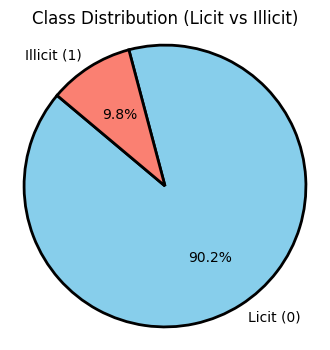

In [10]:
# --- VISUALIZATION: Class Imbalance (Pie Chart - Styled) ---
plt.figure(figsize=(4, 4))

sizes = df_labeled['label'].value_counts().sort_index().values
labels = ['Licit (0)', 'Illicit (1)']
colors = ['skyblue', 'salmon']

plt.pie(
    sizes,
    labels=labels,
    colors=colors,
    autopct='%1.1f%%',
    startangle=140,
    wedgeprops={
        'edgecolor': 'black',
        'linewidth': 2,
        'antialiased': True
    }
)

plt.title('Class Distribution (Licit vs Illicit)')
plt.axis('equal')
plt.show()


In [11]:
# ---  SPLIT ---

# Split labeled data randomly (e.g., 70% train, 30% test)
df_train, df_test = train_test_split(df_labeled, test_size=0.3, random_state=42, stratify=df_labeled['label'])

# Masks for training and testing nodes (optional, if you need boolean masks for PyG or NetworkX)
train_mask = df_labeled['txId'].isin(df_train['txId'])
test_mask = df_labeled['txId'].isin(df_test['txId'])

print(f"Train samples: {train_mask.sum()}")
print(f"Test samples: {test_mask.sum()}")

Train samples: 32594
Test samples: 13970


# 1- Traditional approach (node features + ML model)

In [12]:
# ---------------------------------------------------------
# 3. TRADITIONAL ML (Graph Metrics + Random Forest)
# ---------------------------------------------------------
print("Building Graph for Metrics...")

import networkx as nx

# Create NetworkX DiGraph from edges
G = nx.from_pandas_edgelist(df_edges, 'txId1', 'txId2', create_using=nx.DiGraph())

# Optional: focus on the giant weakly connected component for visualization
G_giant_nodes = max(nx.weakly_connected_components(G), key=len)
G_giant = G.subgraph(G_giant_nodes).copy()

print(f"Graph created: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")


Building Graph for Metrics...
Graph created: 203769 nodes, 234355 edges


In [13]:
# Take a random sample of nodes (e.g. 10% of the graph or max 10,000 nodes)
sample_size = min(10000, int(0.1 * G.number_of_nodes()))
sample_nodes = np.random.choice(list(G.nodes()), size=sample_size, replace=False)

# Create subgraph
G_small = G.subgraph(sample_nodes).copy()

print("Original Graph:", G.number_of_nodes(), "nodes")
print("Sampled Graph:", G_small.number_of_nodes(), "nodes")


Original Graph: 203769 nodes
Sampled Graph: 10000 nodes


In [14]:
print("Calculating graph metrics (sampled graph)...")

df_labeled = df_labeled[df_labeled['txId'].isin(G_small.nodes())].copy()

df_labeled['in_degree']  = df_labeled['txId'].map(dict(G_giant.in_degree())).fillna(0)
df_labeled['out_degree'] = df_labeled['txId'].map(dict(G_giant.out_degree())).fillna(0)

degree_centrality = nx.degree_centrality(G_giant)
print("degree centrality : ",degree_centrality)

closeness_centrality = nx.closeness_centrality(G_giant)
print("closeness_centrality : ", closeness_centrality)

betweenness_centrality = nx.betweenness_centrality(G_giant)
print("betweenness_centrality : ", betweenness_centrality)

pagerank = nx.pagerank(G_giant)
print("pagerank : ", pagerank)

clustering_coeff = nx.clustering(G_giant.to_undirected())
print("clustering_coeff : ", clustering_coeff)

df_labeled['degree_centrality'] = df_labeled['txId'].map(degree_centrality).fillna(0)

df_labeled['closeness_centrality'] = df_labeled['txId'].map(closeness_centrality).fillna(0)
df_labeled['betweenness_centrality'] = df_labeled['txId'].map(betweenness_centrality).fillna(0)
df_labeled['pagerank'] = df_labeled['txId'].map(pagerank).fillna(0)
df_labeled['clustering_coeff'] = df_labeled['txId'].map(clustering_coeff).fillna(0)

triangles = nx.triangles(G_giant.to_undirected())
df_labeled['triangles'] = df_labeled['txId'].map(triangles).fillna(0)

print("✅ Graph metrics added to sampled dataframe!")


Calculating graph metrics (sampled graph)...
✅ Graph metrics added to sampled dataframe!


Top 10 nodes by degree centrality:
        Node  Degree Centrality
0      89273           0.036680
1  232438397           0.020434
2    2881273           0.018150
3  230658142           0.017007
4    2758467           0.013453
5    2881274           0.012311
6  232029206           0.007615
7   43560505           0.006346
8    2880930           0.006219
9   27405707           0.005077


/tmp/ipykernel_47/2790333150.py:25: MatplotlibDeprecationWarning: Unable to determine Axes to steal space for Colorbar. Using gca(), but will raise in the future. Either provide the *cax* argument to use as the Axes for the Colorbar, provide the *ax* argument to steal space from it, or add *mappable* to an Axes.
  plt.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=cmap), label='Degree Centrality')


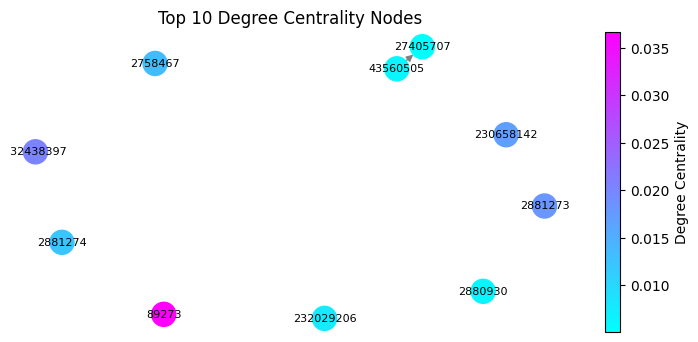

In [15]:
# Degree centrality.
degree_centrality = nx.degree_centrality(G_giant)
top_degree_centrality = sorted(degree_centrality.items(), key=lambda x: x[1], reverse=True)[:10]
df_top_degree_centrality = pd.DataFrame(top_degree_centrality, columns=['Node', 'Degree Centrality'])

print("Top 10 nodes by degree centrality:")
print("==================================")
print(df_top_degree_centrality)

top_nodes_by_ = df_top_degree_centrality['Node'].tolist()
subgraph = G_giant.subgraph(top_nodes_by_)
node_color = [degree_centrality[node] for node in subgraph.nodes()]
norm = mpl.colors.Normalize(vmin=min(node_color), vmax=max(node_color))
node_color_normalized = [norm(value) for value in node_color]
cmap = plt.cm.cool

# -------- #
# Plotting #
# -------- #
plt.figure(figsize=(7, 3))

nx.draw(subgraph, with_labels=True, node_size=300, edge_color='gray', font_size=8, 
        node_color=node_color_normalized, cmap=cmap)
plt.title('Top 10 Degree Centrality Nodes')
plt.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=cmap), label='Degree Centrality')
plt.show()

Top 10 nodes by betweenness centrality:
        Node  Betweenness Centrality
0  231994209                0.000230
1   14883414                0.000230
2   91798399                0.000229
3   91293757                0.000229
4   86711289                0.000229
5  231994205                0.000229
6   60494022                0.000228
7  230582115                0.000228
8  231994202                0.000228
9  231994213                0.000228


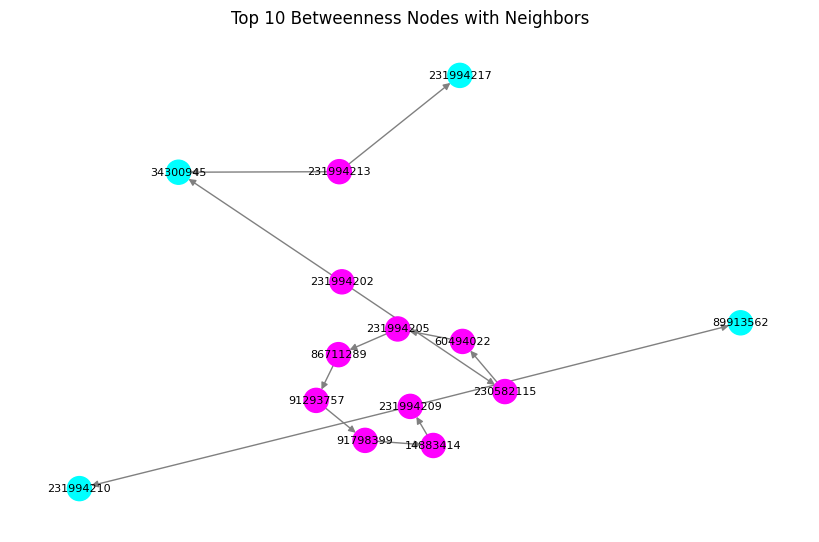

In [16]:
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

# --- Top 10 nodes by betweenness centrality ---
top_betweenness_centrality = sorted(betweenness_centrality.items(), key=lambda x: x[1], reverse=True)[:10]
df_top_betweenness_centrality = pd.DataFrame(top_betweenness_centrality, columns=['Node', 'Betweenness Centrality'])

print("Top 10 nodes by betweenness centrality:")
print("=======================================")
print(df_top_betweenness_centrality)

# --- Top nodes ---
top_nodes = df_top_betweenness_centrality['Node'].tolist()

# --- Include neighbors to show edges ---
nodes_to_plot = set(top_nodes)
for n in top_nodes:
    nodes_to_plot.update(G.neighbors(n))  # add neighbors

subgraph = G.subgraph(nodes_to_plot).copy()

# --- Node colors: highlight top nodes ---
node_color = []
for node in subgraph.nodes():
    if node in top_nodes:
        node_color.append(1.0)  # top nodes highlighted
    else:
        node_color.append(0.5)  # neighbors

# --- Plot ---
plt.figure(figsize=(8, 5))
nx.draw(subgraph,
        with_labels=True,
        node_size=300,
        edge_color='gray',
        font_size=8,
        node_color=node_color,
        cmap=plt.cm.cool)
plt.title('Top 10 Betweenness Nodes with Neighbors')
plt.show()


Top 10 nodes by closeness centrality:
        Node  Closeness Centrality
0  232438397              0.022928
1    2881273              0.018657
2   92491280              0.016633
3  230658142              0.016571
4    2881274              0.014875
5    2758467              0.013752
6  205337217              0.013067
7  205336060              0.010773
8    2773281              0.009172
9  232438575              0.007992


/tmp/ipykernel_47/3771673456.py:53: MatplotlibDeprecationWarning: Unable to determine Axes to steal space for Colorbar. Using gca(), but will raise in the future. Either provide the *cax* argument to use as the Axes for the Colorbar, provide the *ax* argument to steal space from it, or add *mappable* to an Axes.
  plt.colorbar(sm, label='Closeness Centrality')


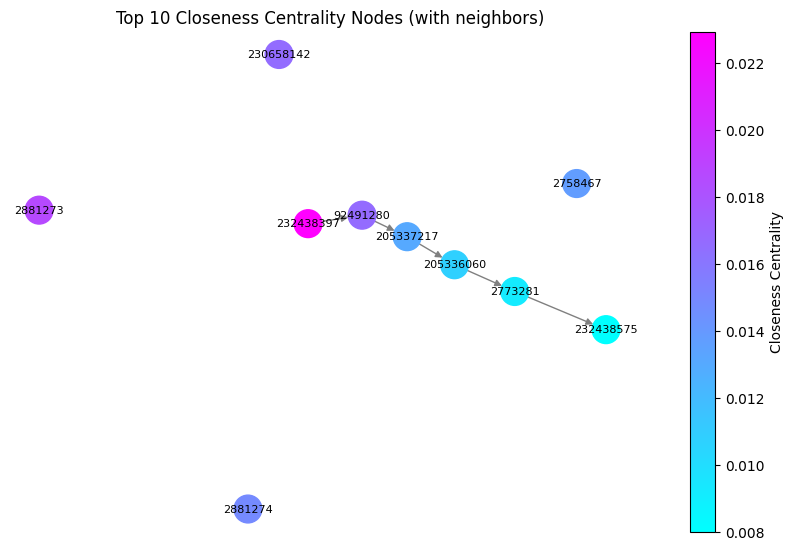

In [17]:
# --- Closeness centrality ---

# --- Top 10 nodes by closeness ---
top_closeness_centrality = sorted(closeness_centrality.items(), key=lambda x: x[1], reverse=True)[:10]
df_top_closeness = pd.DataFrame(top_closeness_centrality, columns=['Node', 'Closeness Centrality'])

print("Top 10 nodes by closeness centrality:")
print("=====================================")
print(df_top_closeness)

# --- Ensure nodes exist in G_giant ---
graph_node_type = type(list(G_giant.nodes())[0])
top_nodes = [graph_node_type(node) for node in df_top_closeness['Node']]
top_nodes_filtered = [node for node in top_nodes if node in G_giant]

if len(top_nodes_filtered) == 0:
    print("No top nodes exist in the graph!")
else:
    # --- Include a few neighbors to show edges ---
    nodes_to_plot = set(top_nodes_filtered)
    for node in top_nodes_filtered:
        neighbors = list(G_giant.neighbors(node))[:2]  # take up to 2 neighbors
        nodes_to_plot.update(neighbors)

    subgraph = G_giant.subgraph(nodes_to_plot).copy()

    # --- Node colors: highlight top nodes ---
    node_color = []
    for node in subgraph.nodes():
        if node in top_nodes_filtered:
            node_color.append(closeness_centrality.get(node, 0))
        else:
            node_color.append(0.0)  # neighbors get low value

    # --- Normalize colors ---
    norm = mpl.colors.Normalize(vmin=min(node_color), vmax=max(node_color))
    node_color_normalized = [norm(value) for value in node_color]
    cmap = plt.cm.cool

    # --- Plot ---
    plt.figure(figsize=(8, 5))
    nx.draw(subgraph,
            with_labels=True,
            node_size=400,
            edge_color='gray',
            font_size=8,
            node_color=node_color_normalized,
            cmap=cmap)
    
    # --- Colorbar ---
    sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    plt.colorbar(sm, label='Closeness Centrality')

    plt.title('Top 10 Closeness Centrality Nodes (with neighbors)')
    plt.show()


In [18]:
# 1. Regenerate masks based on the CURRENT dataframe's time_steps
# (This ensures the mask length matches X length)
train_mask_sample = df_labeled['time_step'] <= 34
test_mask_sample = df_labeled['time_step'] > 34

# 2. Define Features and Target
# We assume you have calculated these metrics. If some are missing, remove them from the list.
feature_cols = [c for c in df_labeled.columns if 'feat_' in c] + [
    'in_degree', 'out_degree', 'degree_centrality', 'closeness_centrality',
    'betweenness_centrality', 'pagerank', 'clustering_coeff', 'triangles'
]

# Filter to only columns that actually exist in your dataframe
existing_cols = [c for c in feature_cols if c in df_labeled.columns]
print(f"Using features: {existing_cols}")

X = df_labeled[existing_cols].values
y = df_labeled['label'].values

# 3. Perform the Split using the NEW sample masks
X_train, y_train = X[train_mask_sample], y[train_mask_sample]
X_test, y_test = X[test_mask_sample], y[test_mask_sample]

print(f"Training samples: {X_train.shape[0]}, Testing samples: {X_test.shape[0]}")


Using features: ['feat_0', 'feat_1', 'feat_2', 'feat_3', 'feat_4', 'feat_5', 'feat_6', 'feat_7', 'feat_8', 'feat_9', 'feat_10', 'feat_11', 'feat_12', 'feat_13', 'feat_14', 'feat_15', 'feat_16', 'feat_17', 'feat_18', 'feat_19', 'feat_20', 'feat_21', 'feat_22', 'feat_23', 'feat_24', 'feat_25', 'feat_26', 'feat_27', 'feat_28', 'feat_29', 'feat_30', 'feat_31', 'feat_32', 'feat_33', 'feat_34', 'feat_35', 'feat_36', 'feat_37', 'feat_38', 'feat_39', 'feat_40', 'feat_41', 'feat_42', 'feat_43', 'feat_44', 'feat_45', 'feat_46', 'feat_47', 'feat_48', 'feat_49', 'feat_50', 'feat_51', 'feat_52', 'feat_53', 'feat_54', 'feat_55', 'feat_56', 'feat_57', 'feat_58', 'feat_59', 'feat_60', 'feat_61', 'feat_62', 'feat_63', 'feat_64', 'feat_65', 'feat_66', 'feat_67', 'feat_68', 'feat_69', 'feat_70', 'feat_71', 'feat_72', 'feat_73', 'feat_74', 'feat_75', 'feat_76', 'feat_77', 'feat_78', 'feat_79', 'feat_80', 'feat_81', 'feat_82', 'feat_83', 'feat_84', 'feat_85', 'feat_86', 'feat_87', 'feat_88', 'feat_89', 'fe

In [19]:
import warnings
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from tqdm import tqdm

# Suppress the specific warm_start warning from sklearn
warnings.filterwarnings("ignore", message="class_weight presets")

print("Training Random Forest on enhanced graph features...")

# Warm start allows incremental training for tqdm
rf_model = RandomForestClassifier(
    n_estimators=1,  # start with 1, will increment manually
    class_weight='balanced',
    random_state=42,
    n_jobs=-1,
    warm_start=True
)

n_estimators = 100
# Using tqdm to show progress bar
for i in tqdm(range(1, n_estimators + 1), desc="Training Random Forest"):
    rf_model.n_estimators = i
    rf_model.fit(X_train, y_train)

# Evaluate
y_pred = rf_model.predict(X_test)
print("\n--- Traditional ML Results ---")
print(classification_report(y_test, y_pred, target_names=['Licit', 'Illicit']))

# Reset warnings filter (good practice)
warnings.resetwarnings()

Training Random Forest on enhanced graph features...


Training Random Forest: 100%|██████████| 100/100 [00:01<00:00, 69.80it/s]


--- Traditional ML Results ---
              precision    recall  f1-score   support

       Licit       0.98      1.00      0.99       851
     Illicit       1.00      0.63      0.78        52

    accuracy                           0.98       903
   macro avg       0.99      0.82      0.88       903
weighted avg       0.98      0.98      0.98       903



# 2- Shallow embedding approach

In [22]:
from tqdm import tqdm

# ---------------------------------------------------------
# 4. SHALLOW EMBEDDING (Node2Vec)
# ---------------------------------------------------------

print("Generating Node2Vec Embeddings (This may take a few minutes)...")

y = df_labeled['label'].to_numpy().astype(int)

# We run Node2Vec on the graph G constructed earlier
node2vec = Node2Vec(G, dimensions=64, walk_length=10, num_walks=10, workers=4, quiet=True)
n2v_model = node2vec.fit(window=10, min_count=1, batch_words=4)

# Extract Embeddings for labeled nodes (with tqdm)
def get_embedding(tx_id):
    key = str(tx_id)
    if key in n2v_model.wv:
        return n2v_model.wv[key]
    return np.zeros(64)  # Fallback if node isolated

embeddings = np.array([
    get_embedding(tx_id) for tx_id in tqdm(df_labeled['txId'], desc="Extracting embeddings")
])




Generating Node2Vec Embeddings (This may take a few minutes)...


Extracting embeddings: 100%|██████████| 2348/2348 [00:00<00:00, 460348.05it/s]


In [23]:
from sklearn.model_selection import train_test_split

X_train_n2v, X_test_n2v, y_train_n2v, y_test_n2v = train_test_split(
    X_n2v,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train_n2v.shape, X_test_n2v.shape)


(1878, 64) (470, 64)


In [24]:
# Train RF on Embeddings
print("Training Random Forest on Node2Vec Embeddings...")
rf_n2v = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

# tqdm for training progress (manual style)
for _ in tqdm(range(1), desc="Training RF"):
    rf_n2v.fit(X_train_n2v, y_train_n2v)

y_pred_n2v = rf_n2v.predict(X_test_n2v)

print("\n--- Shallow Embedding Results ---")
print(classification_report(y_test_n2v, y_pred_n2v, target_names=['Licit', 'Illicit']))


Training Random Forest on Node2Vec Embeddings...


Training RF: 100%|██████████| 1/1 [00:00<00:00,  1.90it/s]


--- Shallow Embedding Results ---
              precision    recall  f1-score   support

       Licit       0.91      1.00      0.95       427
     Illicit       0.50      0.02      0.04        43

    accuracy                           0.91       470
   macro avg       0.71      0.51      0.50       470
weighted avg       0.87      0.91      0.87       470



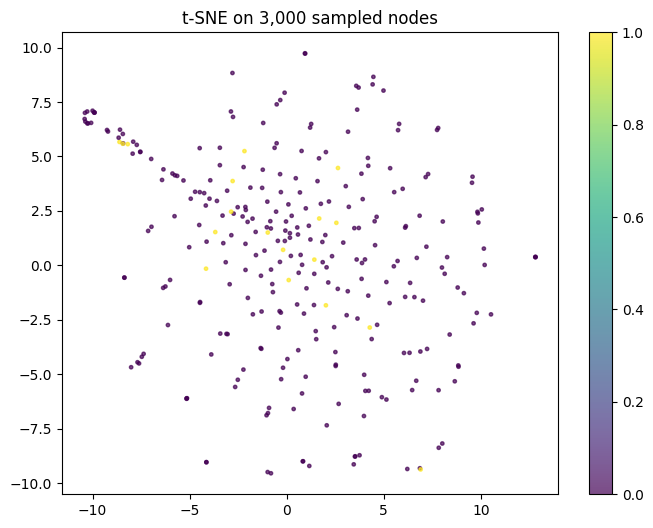

In [25]:
#visualize embeddings using t-SNE
from sklearn.manifold import TSNE

sample_idx = np.random.choice(len(embeddings), size=300, replace=False)
sample_embeddings = embeddings[sample_idx]
sample_labels = df_labeled['label'].iloc[sample_idx]

embeddings_2d = TSNE(n_components=2, random_state=42).fit_transform(sample_embeddings)

plt.figure(figsize=(8, 6))
plt.scatter(embeddings_2d[:, 0], embeddings_2d[:, 1], c=sample_labels, s=6, alpha=0.7)
plt.title("t-SNE on 3,000 sampled nodes")
plt.colorbar()
plt.show()


# 3 - Deep GNN approach

In [29]:
# ---------------------------------------------------------
# 5.1 GRAPH DATA PREPARATION (PyG)
# ---------------------------------------------------------
print("Preparing Data for Deep Learning...")

# We need to map Transaction IDs to continuous indices (0 to N) for PyTorch
node_ids = df_merged['txId'].unique()
id_map = {id: i for i, id in enumerate(node_ids)}

# Create Edge Index
src = df_edges['txId1'].map(id_map).values
dst = df_edges['txId2'].map(id_map).values
edge_index = torch.tensor([src, dst], dtype=torch.long)

# Create Feature Matrix (Sort df by mapped ID to ensure alignment)
df_merged['mapped_id'] = df_merged['txId'].map(id_map)
df_merged = df_merged.sort_values('mapped_id')
feature_cols = [f'feat_{i}' for i in range(165)]
x = torch.tensor(df_merged[feature_cols].values, dtype=torch.float)

# Labels (-1 for unknown/unlabeled nodes)
# Map classes again for the full graph
y_full = df_merged['class'].map({'1': 1, '2': 0, 'unknown': -1}).values
y = torch.tensor(y_full, dtype=torch.long)

# Create Masks based on Time Step
time_steps = torch.tensor(df_merged['time_step'].values)

# Only train on labeled nodes (y != -1) AND time <= 34
train_mask_pyg = (y != -1) & (time_steps <= 34) 
test_mask_pyg = (y != -1) & (time_steps > 34)

# Create PyG Data Object
data = Data(x=x, edge_index=edge_index, y=y).to(device)

# Calculate Class Weights for Imbalance
# (Weight = Total / (Num_Classes * Count))
n_illicit = (y[train_mask_pyg] == 1).sum().item()
n_licit = (y[train_mask_pyg] == 0).sum().item()
weight = torch.tensor([1.0, n_licit / n_illicit]).to(device) # Boost Illicit penalty
print(f"Class Weights: {weight}")

Preparing Data for Deep Learning...
Class Weights: tensor([1.0000, 7.6349], device='cuda:0')


In [30]:
# ---------------------------------------------------------
# 5.2 MODEL DEFINITIONS
# ---------------------------------------------------------

class GCN(torch.nn.Module):
    def __init__(self, hidden_channels):
        super(GCN, self).__init__()
        self.conv1 = GCNConv(data.num_node_features, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, 2)
    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = x.relu()
        x = F.dropout(x, p=0.5, training=self.training)
        x = self.conv2(x, edge_index)
        return x

class GAT(torch.nn.Module):
    def __init__(self, hidden_channels, heads=2):
        super(GAT, self).__init__()
        # GAT with Multi-head attention
        self.conv1 = GATConv(data.num_node_features, hidden_channels, heads=heads, dropout=0.5)
        # Output heads=1 for classification
        self.conv2 = GATConv(hidden_channels * heads, 2, heads=1, concat=False, dropout=0.5)

    def forward(self, x, edge_index):
        x = F.dropout(x, p=0.5, training=self.training)
        x = self.conv1(x, edge_index)
        x = F.elu(x)
        x = F.dropout(x, p=0.5, training=self.training)
        x = self.conv2(x, edge_index)
        return x

In [31]:
# ---------------------------------------------------------
# 5.3 TRAINING & EVALUATION
# ---------------------------------------------------------

def train_evaluate(model_name, model, data, epochs=100):
    print(f"\nTraining {model_name}...")
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
    loss_fn = torch.nn.CrossEntropyLoss(weight=weight) # Handle imbalance

    # Training List for plotting
    losses = []

    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        out = model(data.x, data.edge_index)
        loss = loss_fn(out[train_mask_pyg], data.y[train_mask_pyg])
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
        
        if epoch % 20 == 0:
            print(f"Epoch {epoch} | Loss: {loss.item():.4f}")

    # Evaluation
    model.eval()
    _, pred = model(data.x, data.edge_index).max(dim=1)
    
    # Only evaluate on Test Mask
    y_true_test = data.y[test_mask_pyg].cpu().numpy()
    y_pred_test = pred[test_mask_pyg].cpu().numpy()
    
    print(f"--- {model_name} Results ---")
    print(classification_report(y_true_test, y_pred_test, target_names=['Licit', 'Illicit']))
    
    return losses, y_true_test, y_pred_test

# --- RUN GCN ---
gcn_model = GCN(hidden_channels=128)
gcn_losses, y_true_gcn, y_pred_gcn = train_evaluate("GCN", gcn_model, data)

# --- RUN GAT ---
gat_model = GAT(hidden_channels=64)
gat_losses, y_true_gat, y_pred_gat = train_evaluate("GAT", gat_model, data)


Training GCN...
Epoch 0 | Loss: 0.9043
Epoch 20 | Loss: 0.3069
Epoch 40 | Loss: 0.2377
Epoch 60 | Loss: 0.2092
Epoch 80 | Loss: 0.1876
--- GCN Results ---
              precision    recall  f1-score   support

       Licit       0.97      0.94      0.96     15587
     Illicit       0.40      0.53      0.46      1083

    accuracy                           0.92     16670
   macro avg       0.68      0.74      0.71     16670
weighted avg       0.93      0.92      0.92     16670


Training GAT...
Epoch 0 | Loss: 1.4946
Epoch 20 | Loss: 0.5562
Epoch 40 | Loss: 0.5057
Epoch 60 | Loss: 0.4927
Epoch 80 | Loss: 0.4920
--- GAT Results ---
              precision    recall  f1-score   support

       Licit       0.99      0.61      0.75     15587
     Illicit       0.14      0.91      0.24      1083

    accuracy                           0.63     16670
   macro avg       0.56      0.76      0.50     16670
weighted avg       0.93      0.63      0.72     16670



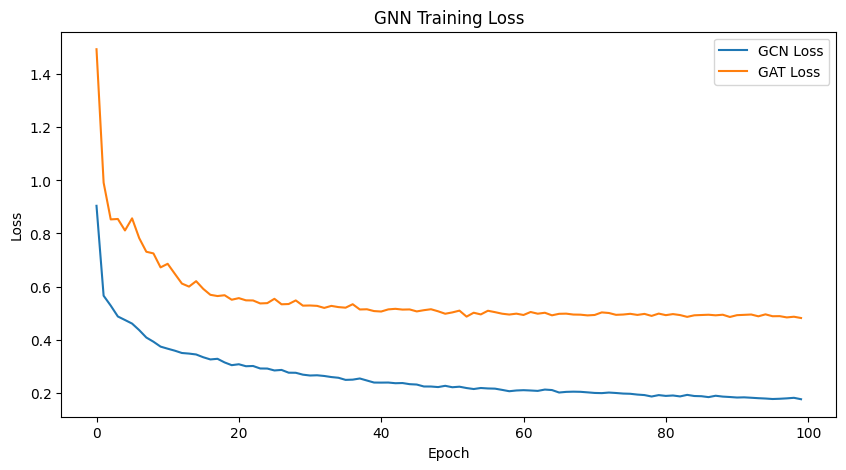

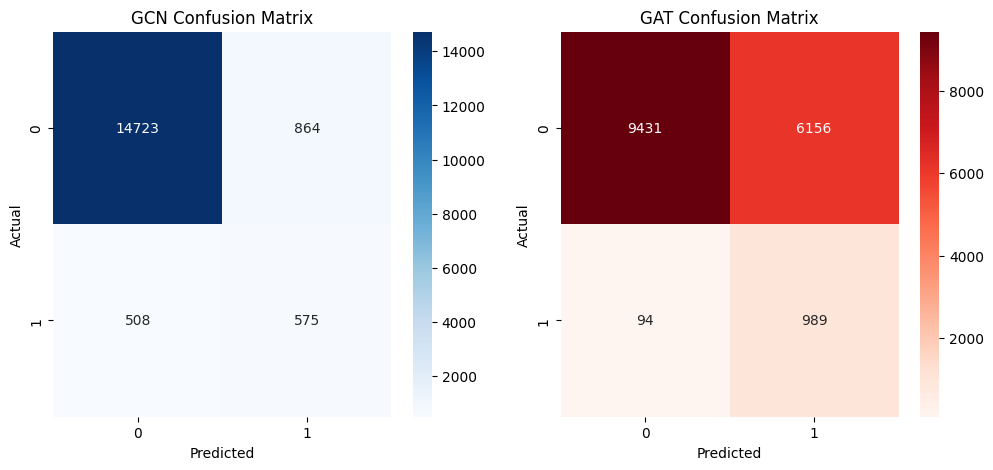

In [32]:
# ---------------------------------------------------------
# 6. VISUALIZATION
# ---------------------------------------------------------

# 1. Loss Curve Comparison
plt.figure(figsize=(10, 5))
plt.plot(gcn_losses, label='GCN Loss')
plt.plot(gat_losses, label='GAT Loss')
plt.title('GNN Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

# 2. Confusion Matrix Comparison
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(confusion_matrix(y_true_gcn, y_pred_gcn), annot=True, fmt='d', cmap='Blues', ax=ax[0])
ax[0].set_title('GCN Confusion Matrix')
ax[0].set_xlabel('Predicted')
ax[0].set_ylabel('Actual')

sns.heatmap(confusion_matrix(y_true_gat, y_pred_gat), annot=True, fmt='d', cmap='Reds', ax=ax[1])
ax[1].set_title('GAT Confusion Matrix')
ax[1].set_xlabel('Predicted')
ax[1].set_ylabel('Actual')

plt.show()